In [34]:
!pip install requests pandas matplotlib nltk scikit-learn wordcloud

In [35]:
import requests
import pandas as pd
import time

In [36]:
# CONFIGURATION
# Keep your API key private. Do not paste it into a notebook that you will publish.
# You can set GUARDIAN_API_KEY in your environment, or enter it at the hidden prompt.
import os
from getpass import getpass

API_KEY = os.environ.get("GUARDIAN_API_KEY", "").strip()
if not API_KEY:
    API_KEY = getpass("Enter your Guardian API key (hidden): ").strip()
if not API_KEY:
    raise ValueError("Guardian API key required: https://open-platform.theguardian.com/")

BASE_URL = "https://content.guardianapis.com/search"

QUERIES = [
    "artificial intelligence",
    "AI regulation",
    "machine learning"
]

FROM_DATE = "2018-01-01"
TO_DATE = "2024-12-31"
PAGES_PER_QUERY = 25
PAGE_SIZE = 50


In [37]:

# FUNCTION 1: COLLECT DATA


def collect_guardian_data(api_key, query, from_date, to_date, max_pages=25):
    all_results = []

    print(f"\nStarting collection for: {query}")
    print(f"Date range: {from_date} to {to_date}")

    for page in range(1, max_pages + 1):
        params = {
            "api-key": api_key,
            "q": query,
            "from-date": from_date,
            "to-date": to_date,
            "page-size": PAGE_SIZE,
            "page": page,
            "show-fields": "bodyText,headline,trailText"
        }

        response = requests.get(BASE_URL, params=params)
        data = response.json()

        if response.status_code != 200:
            print(f"Stopped on page {page}. Error: {response.status_code}")
            break

        results = data["response"]["results"]

        if len(results) == 0:
            print(f"No more results on page {page}.")
            break

        for item in results:
            all_results.append({
                "query": query,
                "date": item.get("webPublicationDate"),
                "title": item.get("fields", {}).get("headline"),
                "trail_text": item.get("fields", {}).get("trailText"),
                "content": item.get("fields", {}).get("bodyText"),
                "section": item.get("sectionName"),
                "url": item.get("webUrl")
            })

        print(f"Page {page}: collected {len(results)} articles")
        time.sleep(0.5)

    return pd.DataFrame(all_results)

In [38]:

# FUNCTION 2: COLLECT ALL QUERIES


def collect_all_queries(api_key, queries, from_date, to_date, max_pages=25):
    dataframes = []

    for query in queries:
        df_query = collect_guardian_data(
            api_key=api_key,
            query=query,
            from_date=from_date,
            to_date=to_date,
            max_pages=max_pages
        )
        dataframes.append(df_query)

    combined_df = pd.concat(dataframes, ignore_index=True)
    return combined_df

In [ ]:

# RUN DATA COLLECTION


df = collect_all_queries(
    api_key=API_KEY,
    queries=QUERIES,
    from_date=FROM_DATE,
    to_date=TO_DATE,
    max_pages=PAGES_PER_QUERY
)

print("\nDataset shape before cleaning:", df.shape)
df.head()

In [40]:

# IMPROVED CLEANING FOR STEP 1


print("Before cleaning:", df.shape)

# 1. Remove duplicate articles using URL instead of title
df = df.drop_duplicates(subset=["url"]).reset_index(drop=True)

# 2. Fill missing text values
df["title"] = df["title"].fillna("").astype(str)
df["trail_text"] = df["trail_text"].fillna("").astype(str)
df["content"] = df["content"].fillna("").astype(str)

# 3. Create one full text column for later NLP work
df["full_text"] = (
    df["title"].str.strip() + " " +
    df["trail_text"].str.strip() + " " +
    df["content"].str.strip()
).str.strip()

# 4. Remove rows where full_text is empty
df = df[df["full_text"].str.len() > 0].reset_index(drop=True)

# 5. Convert date column to datetime for later EDA
df["date"] = pd.to_datetime(df["date"], errors="coerce")

print("After cleaning:", df.shape)
df.head()

Before cleaning: (3750, 7)
After cleaning: (3136, 8)


,query,date,title,trail_text,content,section,url,full_text
0,artificial intelligence,2024-12-11 04:49:01+00:00,‘It’s beyond human scale’: AFP defends use of ...,Australian federal police says it has ‘no choi...,The Australian federal police says it had “no ...,Technology,https://www.theguardian.com/technology/2024/de...,‘It’s beyond human scale’: AFP defends use of ...
1,artificial intelligence,2024-09-04 15:00:42+00:00,Labor considers an artificial intelligence act...,‘We need more people to use AI and to do that ...,The Australian government is considering a Eur...,Australia news,https://www.theguardian.com/australia-news/art...,Labor considers an artificial intelligence act...
2,artificial intelligence,2024-04-08 06:00:26+00:00,Artists’ AI dilemma: can artificial intelligen...,Pierre Huyghe’s uncanny machine-human hybrids ...,Two people dressed in black are kneeling on th...,Art and design,https://www.theguardian.com/artanddesign/2024/...,Artists’ AI dilemma: can artificial intelligen...
3,artificial intelligence,2024-04-29 16:36:02+00:00,OpenAI to use FT journalism to train artificia...,"Under deal, ChatGPT users will receive summari...",The Financial Times has struck a deal with the...,Media,https://www.theguardian.com/media/2024/apr/29/...,OpenAI to use FT journalism to train artificia...
4,artificial intelligence,2024-04-30 22:47:44+00:00,Amazon sales soar with boost from artificial i...,Revenue at Amazon Web Services increases to $2...,Amazon profits soared once again in the first ...,Technology,https://www.theguardian.com/technology/2024/ap...,Amazon sales soar with boost from artificial i...


In [41]:
# =========================
# QUICK DATA CHECK
# =========================

print("Missing dates:", df["date"].isna().sum())
print("Empty full_text rows:", (df["full_text"].str.len() == 0).sum())
print("Duplicate URLs:", df.duplicated(subset=["url"]).sum())

Missing dates: 0
Empty full_text rows: 0
Duplicate URLs: 0


In [42]:

# SAVE DATASET

df.to_csv("guardian_ai_dataset.csv", index=False)

print("Final dataset shape:", df.shape)
print("File saved as: guardian_ai_dataset.csv")

In [ ]:

# CHECK DATA QUALITY


print(df.info())
print("\nColumns:")
print(df.columns.tolist())

print("\nSample full text:")
print(df["full_text"].iloc[0][:500])

Word Count Summary (Before Cleaning):
count     3136.000000
mean       921.170599
std        690.269757
min         14.000000
25%        585.000000
50%        786.000000
75%       1037.250000
max      10996.000000
Name: word_count, dtype: float64


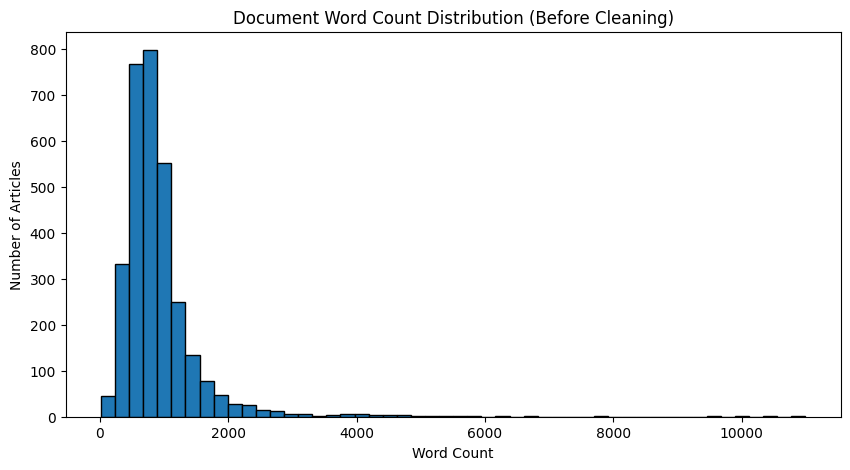

In [44]:

# EDA STEP 1: DOCUMENT LENGTH (BEFORE CLEANING)


# Create document length columns
df["char_count"] = df["full_text"].str.len()
df["word_count"] = df["full_text"].str.split().str.len()

# Summary statistics
print("Word Count Summary (Before Cleaning):")
print(df["word_count"].describe())

# Visualisation
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.hist(df["word_count"], bins=50, edgecolor="black")
plt.title("Document Word Count Distribution (Before Cleaning)")
plt.xlabel("Word Count")
plt.ylabel("Number of Articles")
plt.show()

In [45]:

# EDA STEP 2: REMOVE OUTLIERS


print("Before filtering:", df.shape)

# Remove very short documents
df = df[df["word_count"] >= 50]

# Remove very long documents
df = df[df["word_count"] <= 3000]

print("After filtering:", df.shape)

Before filtering: (3136, 10)
After filtering: (3080, 10)


Word Count Summary (After Cleaning):
count    3080.000000
mean      860.758442
std       427.879707
min        55.000000
25%       583.000000
50%       778.500000
75%      1020.250000
max      2988.000000
Name: word_count, dtype: float64


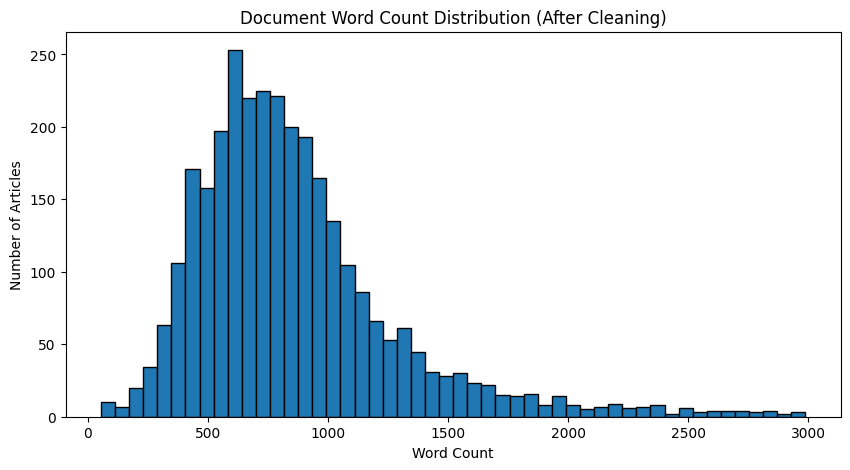

In [46]:

# EDA STEP 3: DOCUMENT LENGTH (AFTER CLEANING)


# Summary statistics after cleaning
print("Word Count Summary (After Cleaning):")
print(df["word_count"].describe())

# Visualisation
plt.figure(figsize=(10, 5))
plt.hist(df["word_count"], bins=50, edgecolor="black")
plt.title("Document Word Count Distribution (After Cleaning)")
plt.xlabel("Word Count")
plt.ylabel("Number of Articles")
plt.show()

### Document Length Analysis

The initial distribution of document lengths showed a right-skewed pattern with several extreme outliers. Most articles were concentrated between approximately 300 and 1500 words, while some documents were very short and others exceeded 10,000 words.

To improve the quality of topic modelling, documents with fewer than 50 words and more than 3000 words were removed. Short documents often lack sufficient semantic information, while very long documents can dominate topic distributions and introduce bias.

After filtering, the distribution became more balanced, with most documents falling within a consistent range. This preprocessing step ensures more reliable and interpretable topic modelling results.

In [47]:

# EDA STEP 4: ARTICLE SECTIONS


section_counts = df["section"].value_counts()

print("Top Sections:")
print(section_counts.head(10))

Top Sections:
section
Technology        580
Opinion           295
World news        234
Australia news    233
US news           193
Business          178
Life and style    120
Society           112
Football          110
Film               93
Name: count, dtype: int64


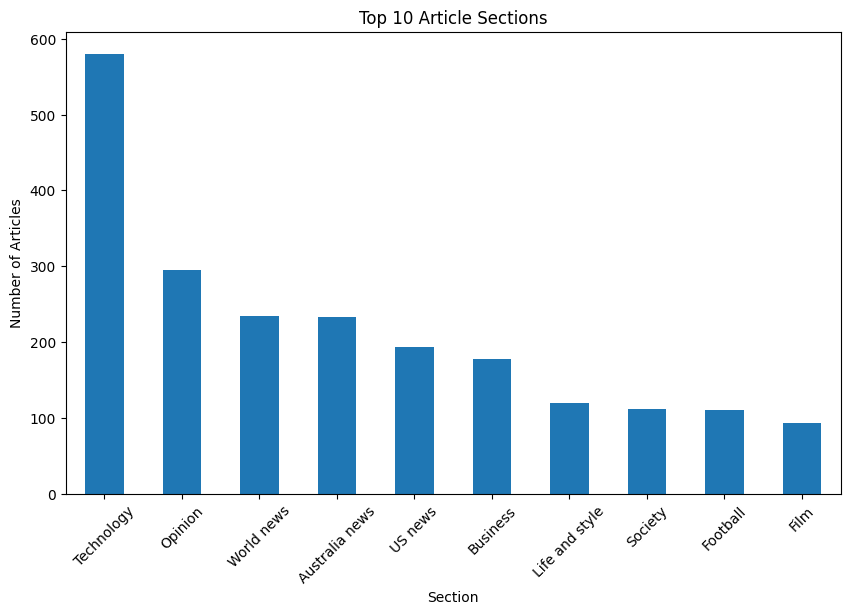

In [48]:

# VISUALISE ARTICLE SECTIONS


import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
section_counts.head(10).plot(kind="bar")
plt.title("Top 10 Article Sections")
plt.xlabel("Section")
plt.ylabel("Number of Articles")
plt.xticks(rotation=45)
plt.show()

### Article Section Analysis

The dataset contains articles from a variety of sections, with "Technology" being the most dominant category. This is expected given the focus on artificial intelligence and machine learning topics.

However, the presence of other sections such as "World news", "Business", "Society", and "Opinion" indicates that AI is discussed across multiple domains. This diversity is beneficial for topic modelling, as it allows the models to identify a wider range of themes and contextual variations.

Overall, the dataset provides a good balance between domain focus and thematic diversity, which is suitable for meaningful topic extraction.

In [49]:

# EDA STEP 5: ARTICLES OVER TIME


# Extract year
df["year"] = df["date"].dt.year

year_counts = df["year"].value_counts().sort_index()

print(year_counts)

year
2021       1
2022      46
2023     755
2024    2278
Name: count, dtype: int64


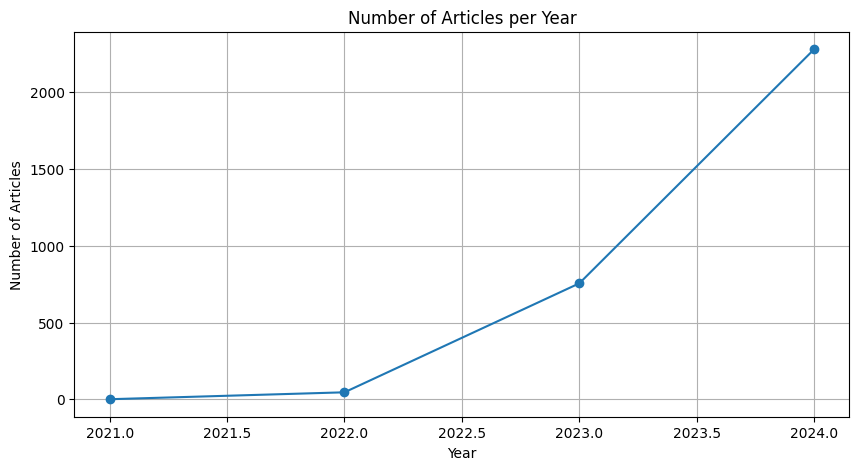

In [50]:
plt.figure(figsize=(10, 5))
year_counts.plot(kind="line", marker="o")
plt.title("Number of Articles per Year")
plt.xlabel("Year")
plt.ylabel("Number of Articles")
plt.grid()
plt.show()

### Temporal Analysis of Articles

The number of articles shows a strong increasing trend over time, with a sharp rise in 2023 and 2024. This reflects the growing importance and public interest in artificial intelligence and related technologies.

However, it is important to consider that this trend may also be influenced by the data collection process. News APIs often prioritise more recent content, and the query terms used may return a higher number of recent articles. Therefore, the observed increase may be partially affected by sampling bias rather than purely representing real-world growth.

Despite this limitation, the dataset still captures a meaningful temporal trend, which can be useful for analysing how topics evolve over time.

## Methodology Overview

This project follows a structured Natural Language Processing (NLP) pipeline to perform topic modelling on a manually collected dataset of news articles.

The workflow consists of the following stages:

1. **Data Collection**  
   Articles were collected using the Guardian API, focusing on topics related to artificial intelligence.

2. **Data Cleaning and Preparation**  
   The dataset was cleaned by removing duplicates, handling missing values, and combining relevant text fields into a single `full_text` column.

3. **Exploratory Data Analysis (EDA)**  
   Various analyses were conducted to understand the dataset, including document length distribution, article categories, and temporal trends.

4. **Text Preprocessing**  
   The text was preprocessed through multiple steps:
   - Lowercasing and removal of punctuation and numbers
   - Stopword removal
   - Lemmatization

5. **Text Representation**  
   The processed text was converted into numerical form using:
   - TF-IDF (for NMF)
   - Count Vectorization (for LDA)

6. **Topic Modelling**  
   Two topic modelling techniques were applied:
   - Non-negative Matrix Factorization (NMF)
   - Latent Dirichlet Allocation (LDA)

7. **Evaluation and Comparison**  
   The models were compared based on topic coherence and interpretability.

This structured approach ensures that the analysis is systematic, reproducible, and suitable for extracting meaningful insights from unstructured text data.

In [51]:

# BASIC TEXT CLEANING


import re

def clean_text(text):
    # Lowercase
    text = text.lower()

    # Remove punctuation and numbers
    text = re.sub(r'[^a-z\s]', '', text)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()

    return text

# Apply cleaning
df["clean_text"] = df["full_text"].apply(clean_text)

# Show example
print("Original:\n", df["full_text"].iloc[0][:300])
print("\nCleaned:\n", df["clean_text"].iloc[0][:300])

Original:
 ‘It’s beyond human scale’: AFP defends use of artificial intelligence to search seized phones and emails Australian federal police says it has ‘no choice’ due to the vast amount of data examined in investigations The Australian federal police says it had “no choice” but to lean into using artificial

Cleaned:
 its beyond human scale afp defends use of artificial intelligence to search seized phones and emails australian federal police says it has no choice due to the vast amount of data examined in investigations the australian federal police says it had no choice but to lean into using artificial intelli


### Basic Text Cleaning

The text data was preprocessed by converting all characters to lowercase, removing punctuation and numerical values, and eliminating extra whitespace. This step ensures that the text is standardised and reduces noise in the dataset.

Lowercasing prevents the same words from being treated as different tokens (e.g., "AI" and "ai"), while removing punctuation and numbers simplifies the text and improves the quality of downstream analysis.

This basic cleaning step prepares the dataset for more advanced preprocessing techniques such as stopword removal and lemmatisation.

In [52]:

# REMOVE STOPWORDS


import nltk
from nltk.corpus import stopwords

# Download stopwords (only runs once)
nltk.download('stopwords')

stop_words = set(stopwords.words('english'))

def remove_stopwords(text):
    words = text.split()
    filtered_words = [word for word in words if word not in stop_words]
    return " ".join(filtered_words)

# Apply stopword removal
df["clean_text"] = df["clean_text"].apply(remove_stopwords)

# Show example
print("After stopword removal:\n")
print(df["clean_text"].iloc[0][:300])

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.


After stopword removal:

beyond human scale afp defends use artificial intelligence search seized phones emails australian federal police says choice due vast amount data examined investigations australian federal police says choice lean using artificial intelligence increasingly using technology search seized phones device


In [53]:

# LEMMATIZATION


from nltk.stem import WordNetLemmatizer
from nltk.corpus import wordnet

# Download WordNet (only once)
nltk.download('wordnet')
nltk.download('omw-1.4')

lemmatizer = WordNetLemmatizer()

def lemmatize_text(text):
    words = text.split()
    lemmatized_words = [lemmatizer.lemmatize(word) for word in words]
    return " ".join(lemmatized_words)

# Apply lemmatization
df["clean_text"] = df["clean_text"].apply(lemmatize_text)

# Show example
print("After lemmatization:\n")
print(df["clean_text"].iloc[0][:300])

[nltk_data] Downloading package wordnet to /root/nltk_data...
[nltk_data] Downloading package omw-1.4 to /root/nltk_data...


After lemmatization:

beyond human scale afp defends use artificial intelligence search seized phone email australian federal police say choice due vast amount data examined investigation australian federal police say choice lean using artificial intelligence increasingly using technology search seized phone device given


### Lemmatization

Lemmatization was applied to reduce words to their base or root form. This helps to group different variations of a word into a single representation (e.g., "running", "runs", and "ran" become "run").

This step improves the quality of topic modelling by reducing redundancy in the vocabulary and ensuring that semantically similar words are treated as the same term.

Although a simple lemmatization approach was used, it is sufficient to improve text consistency and enhance downstream modelling performance.

In [54]:

# TF-IDF VECTORIZATION


from sklearn.feature_extraction.text import TfidfVectorizer

# Create TF-IDF vectorizer
tfidf_vectorizer = TfidfVectorizer(
    max_df=0.95,   # ignore very common words
    min_df=5,      # ignore very rare words
    stop_words='english'
)

# Fit and transform the data
tfidf_matrix = tfidf_vectorizer.fit_transform(df["clean_text"])

print("TF-IDF matrix shape:", tfidf_matrix.shape)

TF-IDF matrix shape: (3080, 16745)


### TF-IDF Vectorization

The cleaned text data was transformed into a numerical representation using TF-IDF (Term Frequency–Inverse Document Frequency). This technique assigns higher importance to words that appear frequently in a document but less frequently across the entire dataset.

The resulting matrix has 3080 documents and 16,745 features, indicating a rich vocabulary within the dataset. TF-IDF helps reduce the influence of very common words while preserving meaningful terms, making it suitable for topic modelling.

This representation will be used as input for topic modelling algorithms such as Latent Dirichlet Allocation (LDA) and Non-negative Matrix Factorization (NMF).

In [55]:

# NMF TOPIC MODELLING


from sklearn.decomposition import NMF

# Set number of topics
num_topics = 10

nmf_model = NMF(n_components=num_topics, random_state=42)

nmf_model.fit(tfidf_matrix)

print("NMF model trained successfully")

NMF model trained successfully


In [56]:

# DISPLAY NMF TOPICS


feature_names = tfidf_vectorizer.get_feature_names_out()

def display_topics(model, feature_names, num_top_words):
    for topic_idx, topic in enumerate(model.components_):
        top_words = [feature_names[i] for i in topic.argsort()[:-num_top_words - 1:-1]]
        print(f"Topic {topic_idx + 1}:")
        print(", ".join(top_words))
        print()

# Display top 10 words per topic
display_topics(nmf_model, feature_names, 10)

Topic 1:
ai, model, technology, human, chatgpt, summit, use, safety, tool, risk

Topic 2:
like, say, life, im, time, thing, people, book, music, feel

Topic 3:
ukraine, russian, russia, military, war, ukrainian, said, israel, attack, putin

Topic 4:
school, student, education, child, teacher, learning, pupil, university, said, exam

Topic 5:
company, bn, openai, nvidia, market, apple, google, tech, chip, microsoft

Topic 6:
trump, election, musk, harris, voter, republican, campaign, president, donald, political

Topic 7:
said, government, health, patient, uk, labour, cancer, nh, people, risk

Topic 8:
image, content, medium, said, video, child, aigenerated, online, platform, deepfake

Topic 9:
league, football, club, game, player, premier, city, regulator, team, season

Topic 10:
gambling, machine, poker, gaming, cashless, government, club, venue, slot, betting



### NMF Topic Interpretation

The NMF model identified 10 distinct topics from the dataset. Each topic is interpreted based on its most significant keywords:

- Topic 1: **Artificial Intelligence & Technology**  
  (ai, model, technology, chatgpt, safety, tool)

- Topic 2: **General / Low-Coherence Topic**  
  (like, say, people, time, thing)  
  This topic appears less meaningful and may represent noise or common language patterns.

- Topic 3: **Ukraine War & International Conflict**  
  (ukraine, russia, war, military, attack)

- Topic 4: **Education & Schools**  
  (school, student, education, teacher, university)

- Topic 5: **Technology Companies & Market**  
  (openai, nvidia, google, microsoft, market)

- Topic 6: **US Politics & Elections**  
  (trump, election, campaign, republican, president)

- Topic 7: **Public Health & Government Policy**  
  (health, patient, government, cancer, nhs)

- Topic 8: **Digital Media & AI Content**  
  (image, video, deepfake, platform, online)

- Topic 9: **Football & Sports**  
  (football, league, club, player, premier)

- Topic 10: **Gambling & Betting Industry**  
  (gambling, poker, betting, casino, slot)

Overall, the model successfully identified several meaningful and interpretable topics, although some topics show lower coherence due to overlapping themes or common vocabulary.

In [57]:

# NMF WITH 8 TOPICS


from sklearn.decomposition import NMF

num_topics_8 = 8

nmf_model_8 = NMF(n_components=num_topics_8, random_state=42)

nmf_model_8.fit(tfidf_matrix)

print("NMF (8 topics) trained successfully")

# Display topics
display_topics(nmf_model_8, feature_names, 10)

NMF (8 topics) trained successfully
Topic 1:
ai, technology, model, human, chatgpt, summit, risk, use, safety, tool

Topic 2:
like, say, time, people, life, thing, im, year, feel, game

Topic 3:
ukraine, russian, russia, said, military, war, ukrainian, israel, attack, security

Topic 4:
school, student, education, child, teacher, learning, pupil, university, said, exam

Topic 5:
company, bn, nvidia, market, openai, apple, google, tech, chip, investor

Topic 6:
trump, election, musk, harris, voter, republican, campaign, president, donald, party

Topic 7:
gambling, club, government, machine, gaming, said, poker, football, league, regulator

Topic 8:
image, content, medium, said, child, video, platform, online, social, aigenerated



### Comparison of NMF Models (10 vs 8 Topics)

Two NMF models were tested using different numbers of topics (10 and 8) to evaluate topic quality and interpretability.

The 10-topic model produced a larger number of distinct themes, including well-defined topics such as Artificial Intelligence, Ukraine War, Education, and Football. However, it also generated some less coherent topics containing generic words, indicating noise in the model.

The 8-topic model resulted in more compact topics, but some themes became overly merged. For example, certain topics combined unrelated concepts such as gambling, sports, and government, reducing interpretability.

Overall, the 10-topic model provided a better balance between topic diversity and clarity, despite the presence of minor noise. Therefore, it was selected as the preferred model for further analysis.

In [58]:

# COUNT VECTORIZATION FOR LDA


from sklearn.feature_extraction.text import CountVectorizer

count_vectorizer = CountVectorizer(
    max_df=0.95,
    min_df=5,
    stop_words='english'
)

count_matrix = count_vectorizer.fit_transform(df["clean_text"])

print("Count matrix shape:", count_matrix.shape)

Count matrix shape: (3080, 16745)


In [59]:

# LDA TOPIC MODELLING


from sklearn.decomposition import LatentDirichletAllocation

num_topics_lda = 10

lda_model = LatentDirichletAllocation(
    n_components=num_topics_lda,
    random_state=42
)

lda_model.fit(count_matrix)

print("LDA model trained successfully")

LDA model trained successfully


In [60]:

# DISPLAY LDA TOPICS


feature_names_lda = count_vectorizer.get_feature_names_out()

display_topics(lda_model, feature_names_lda, 10)

Topic 1:
said, school, student, child, university, education, gambling, year, people, learning

Topic 2:
said, intelligence, government, war, ukraine, security, country, russia, russian, military

Topic 3:
ai, company, said, technology, tech, google, year, new, model, world

Topic 4:
ai, said, company, technology, use, model, tool, intelligence, content, artificial

Topic 5:
said, child, image, police, football, club, abuse, regulator, league, sexual

Topic 6:
people, film, say, machine, like, year, time, life, make, new

Topic 7:
health, patient, cancer, people, said, doctor, new, food, medical, nh

Topic 8:
said, year, company, uk, government, bn, business, labour, water, new

Topic 9:
trump, election, said, people, state, party, political, time, campaign, voter

Topic 10:
say, like, time, year, thing, life, way, people, day, world



### LDA Topic Interpretation

The LDA model identified 10 topics; however, compared to NMF, the topics appear less coherent and more difficult to interpret.

Some topics show meaningful patterns, such as:

- Topic 2: **Ukraine War & International Conflict**  
  (ukraine, russia, war, military, security)

- Topic 3 & 4: **Artificial Intelligence & Technology**  
  (ai, technology, model, company, intelligence)

- Topic 7: **Health & Medical Issues**  
  (health, patient, doctor, medical, cancer)

- Topic 9: **US Politics & Elections**  
  (trump, election, campaign, political, voter)

However, several topics contain common words such as "said", "people", and "time", which reduces interpretability. Some topics also mix unrelated concepts, indicating lower topic coherence.

Overall, the LDA model produces less distinct and less interpretable topics compared to NMF.

### Comparison of NMF and LDA

Two topic modelling approaches were applied: Non-negative Matrix Factorization (NMF) and Latent Dirichlet Allocation (LDA).

The NMF model produced clearer and more interpretable topics, with well-defined themes such as Artificial Intelligence, Ukraine War, Education, and Sports. The topics were more distinct and easier to label.

In contrast, the LDA model generated less coherent topics, often including common words such as "said" and mixing unrelated concepts. This made interpretation more difficult and reduced the overall quality of the topics.

This difference can be attributed to the underlying methods: NMF works well with TF-IDF representations and tends to produce more distinct topics, while LDA relies on probabilistic word distributions and is more sensitive to noise in the data.

Overall, NMF was found to be the more effective method for this dataset.

In [ ]:

# SHOW TOP DOCUMENTS PER NMF TOPIC


import numpy as np

# Get document-topic matrix for NMF
nmf_doc_topic = nmf_model.transform(tfidf_matrix)

def show_top_documents_per_topic(doc_topic_matrix, texts, topic_num, n_top_docs=3):
    # Get indices of top documents for this topic
    top_doc_indices = np.argsort(doc_topic_matrix[:, topic_num])[::-1][:n_top_docs]

    print(f"\n=== Topic {topic_num + 1} - Top Documents ===\n")

    for i, idx in enumerate(top_doc_indices):
        print(f"Document {i+1}:")
        print(texts.iloc[idx][:500])  # show first 500 chars
        print("\n" + "-"*80 + "\n")

# Example: show for first 3 topics
for topic in range(3):
    show_top_documents_per_topic(nmf_doc_topic, df["full_text"], topic)

### Topic Validation Using Sample Documents

To validate the quality of the NMF topics, sample documents with the highest topic weights were examined for selected topics.

The results show that:

- Topic 1 (Artificial Intelligence) contains documents related to AI regulation, risk, and policy discussions.
- Topic 3 (Ukraine War) includes articles focused on military activity and geopolitical developments.
- Topic 2 (General Topic) contains more generic content such as personal narratives and interviews, confirming its lower coherence.

This validation demonstrates that the NMF model successfully captures meaningful themes in the dataset, while also highlighting the presence of less coherent topics. Overall, the results support the effectiveness of NMF for this analysis.


In [63]:

# ENVIRONMENT AND LIBRARY VERSIONS


import sys
import platform
import pandas as pd
import sklearn
import nltk
import matplotlib

print("Python version:", sys.version)
print("Platform:", platform.platform())
print("Processor:", platform.processor())

print("\nLibrary Versions:")
print("pandas:", pd.__version__)
print("scikit-learn:", sklearn.__version__)
print("nltk:", nltk.__version__)
print("matplotlib:", matplotlib.__version__)

Python version: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
Platform: Linux-6.6.113+-x86_64-with-glibc2.35
Processor: x86_64

Library Versions:
pandas: 2.2.2
scikit-learn: 1.6.1
nltk: 3.9.1
matplotlib: 3.10.0


### Environment Details

The experiments were run in a cloud environment using Google Colab. Recording the Python version, operating system details, and library versions helps ensure reproducibility and supports fair comparison between different execution environments.

This is important because topic modelling performance can vary depending on the hardware, operating system, and installed package versions.

In [64]:

# MEASURE TRAINING TIME


import time

# Measure NMF time
start_time = time.time()

nmf_model_timed = NMF(n_components=10, random_state=42)
nmf_model_timed.fit(tfidf_matrix)

nmf_time = time.time() - start_time

print(f"NMF training time: {nmf_time:.2f} seconds")


# Measure LDA time
start_time = time.time()

lda_model_timed = LatentDirichletAllocation(n_components=10, random_state=42)
lda_model_timed.fit(count_matrix)

lda_time = time.time() - start_time

print(f"LDA training time: {lda_time:.2f} seconds")

NMF training time: 6.55 seconds
LDA training time: 39.84 seconds


### Model Training Time Comparison

The training time for both NMF and LDA models was measured to evaluate computational performance.

The results show that NMF trained significantly faster (approximately 6.55 seconds) compared to LDA (approximately 39.84 seconds). This indicates that NMF is more computationally efficient for this dataset.

This difference can be explained by the underlying methodologies. NMF is a matrix factorization technique that works efficiently with TF-IDF representations, while LDA is a probabilistic model that requires iterative estimation of topic distributions, making it more computationally intensive.

These findings suggest that NMF is more suitable for large datasets or real-time applications where performance is important.

## Final Conclusion

This project applied topic modelling techniques to a dataset of news articles related to artificial intelligence.

The analysis followed a structured NLP pipeline, including data collection, cleaning, exploratory analysis, preprocessing, and modelling.

Two topic modelling approaches were evaluated: Non-negative Matrix Factorization (NMF) and Latent Dirichlet Allocation (LDA).

The results show that NMF produced more coherent and interpretable topics, with clearly defined themes such as Artificial Intelligence, Ukraine War, Education, and Sports. In contrast, LDA generated less distinct topics, often including common or irrelevant words, which reduced interpretability.

Additionally, performance analysis demonstrated that NMF was significantly faster than LDA, making it more efficient for practical applications.

Overall, NMF was found to be the most effective method for this dataset, both in terms of topic quality and computational efficiency.

This study highlights the importance of preprocessing, model selection, and evaluation when applying topic modelling to unstructured text data.